### Plan
Baseline models:
* Pick on train step size and max iter for base models; 
    * I will look manually for such a step size, that flatlines as fast as possible, but still gives a smooth curve.
    * for the unregularized models. Regularized versions will use the same. 
    * Then I will cut the amount of iterations
* Train unregularized models.
    * Probabilistic models have threshold of 0.5
* then pick lambda for two regularized model by search on validation set. Pick pick the best model
* Then, obtain test scores - accuracy, recall, precision and most importantly, F1
* Obtain plots 
    * Barplot of Test F1 of the baseline models

extra contribution: 
* evaluate the impact of early stopping and threshold selection:
    * Keep the previous baseline.
    * 1. threshold selection intervention: tune the threshold, given lambda has been selected.
    * 2. early stopping prevention: do early stopping given 40 steps, when training and picking the best lambda. (40 is arbitraty, but OK)
    * then combined 1. and 2. : do early stopping (which affects the best lambda), and then pick the best threshold.
* plots:
    * barplot of test f1 of 4 options (as described above)

This notebook loads the final processed matrices cached by `data-cleaning.ipynb`.


## Load cached processed data

`fit.pkl`, `tune.pkl`, and `valid.pkl` contain processed feature matrices. No cleaning or transformation is rerun here.

In [5]:
import pickle
import random

import matplotlib.pyplot as plt
import numpy as np

from p1.cache import cached_raw
from p1.config import INTERIM_DATA_DIR, RAW_DATA_DIR
from p1.modeling.models import LinearRegressGD, LinearRegressSGD, LogisticRegress
from p1.training import split_rows

CACHE = INTERIM_DATA_DIR / "fd_cleaning_correlated_sub_sample"
# _, _, y_raw, _, _, _ = cached_raw(RAW_DATA_DIR, CACHE)
# load raw from pickle
with (CACHE / "raw.pkl").open("rb") as handle:
    _ = pickle.load(handle)
    _, _, y_raw, _, _, _ = pickle.load(handle)


In [6]:

with (CACHE / "fit.pkl").open("rb") as handle:
    X_fit = pickle.load(handle)
with (CACHE / "tune.pkl").open("rb") as handle:
    X_tune = pickle.load(handle)
with (CACHE / "valid.pkl").open("rb") as handle:
    X_valid = pickle.load(handle)

y = (y_raw == 1).astype(float)
fit_idx, tune_idx, valid_idx = split_rows(y, seed=2026)
y_fit, y_tune, y_valid = y[fit_idx], y[tune_idx], y[valid_idx]
random.seed(2026)

assert X_fit.shape[0] == len(y_fit)
assert X_tune.shape[0] == len(y_tune)
assert X_valid.shape[0] == len(y_valid)
assert X_fit.shape[1] == X_tune.shape[1] == X_valid.shape[1]
print(f"Cached matrices: fit={X_fit.shape}, tune={X_tune.shape}, valid={X_valid.shape}")
print(f"Positive labels: {y.mean():.1%}")

Cached matrices: fit=(5249, 1349), tune=(656, 1349), valid=(657, 1349)
Positive labels: 9.3%


In [7]:
# convert into dense matrices
X_fit = X_fit[:, :]
X_tune = X_tune[:, :]
X_valid = X_valid[:, :]

## Training curves

The following cells use only the processed fitting split. Adjust the step size and maximum iterations manually, then rerun the relevant cell.

In [ ]:
# Full-batch linear regression with gradient descent.
step_size_gd = 0.01
max_iters_gd = 1000
linear_gd = LinearRegressGD(max_iters=max_iters_gd, gamma=step_size_gd, track_history=True)
linear_gd.fit(y_fit, X_fit)

plt.figure(figsize=(7, 4))
plt.plot(linear_gd.train_loss)
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.title(f"LinearRegressGD: gamma={step_size_gd}, max_iters={max_iters_gd}")
plt.grid(alpha=0.3)
plt.show()

MSE GD:   4%|▍         | 45/1000 [00:02<00:47, 20.08iter/s]


KeyboardInterrupt: 

OK, It took ~ 15 min to do 1k steps with step size 0.01. Higher step size (0.1) led to exploding loss. Staying with that


In [ ]:
# Stochastic linear regression with gradient descent.
step_size_sgd = 0.0001
max_iters_sgd = 1000#*len(y_fit)
linear_sgd = LinearRegressSGD(max_iters=max_iters_sgd, gamma=step_size_sgd, track_history=True)
linear_sgd.fit(y_fit, X_fit)

plt.figure(figsize=(7, 4))
plt.plot(linear_sgd.train_loss)
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.title(f"LinearRegressSGD: gamma={step_size_sgd}, max_iters={max_iters_sgd}")
plt.grid(alpha=0.3)# TODO: replace this provisional grid with the final lambda search space.
plt.show()

MSE SGD:   0%|          | 510/5249000 [00:09<28:15:50, 51.58iter/s]


KeyboardInterrupt: 

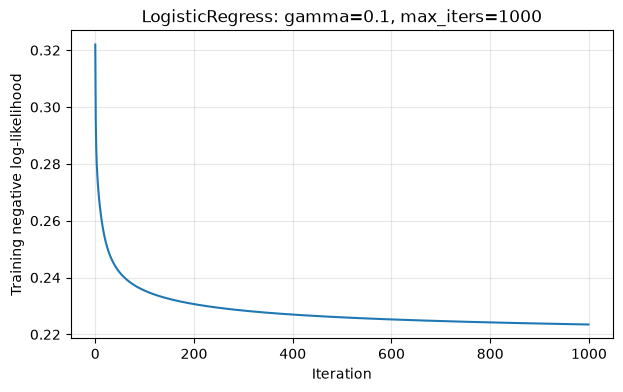

In [44]:
# Unregularized logistic regression.
step_size_logistic = 0.1
max_iters_logistic = 1000
logistic = LogisticRegress(max_iters=max_iters_logistic, gamma=step_size_logistic, track_history=True)
logistic.fit(y_fit, X_fit)

plt.figure(figsize=(7, 4))
plt.plot(logistic.train_loss)
plt.xlabel("Iteration")
plt.ylabel("Training negative log-likelihood")
plt.title(f"LogisticRegress: gamma={step_size_logistic}, max_iters={max_iters_logistic}")
plt.grid(alpha=0.3)
plt.show()

### What happened
- I did not follow my initial plan, because training for 1k steps for LinRGD takes 15min, similarly for LogR
- so I kept the largest step that still resulted in somehow smooth line for 1k entries. Yeah.
- SGD took 5 min. To make it equal I:
- i set sgd iterations to be similar to be comparable gd and logistic regression - so 1k * number of samples
- main cost is perhaphs due to computing the mse in the tracking function

# Training

## unregularized

* regularized models use the same parameters as their corresponding non-regularized ones

In [10]:
max_iters_logistic = 1000
step_size_logistic = 0.1

max_iters_sgd = 1000*len(y_fit)
step_size_sgd = 0.0001

max_iters_gd = 1000
step_size_gd = 0.01

In [ ]:
# Fit the selected unregularized models without storing a loss at every iteration.
linear_gd = LinearRegressGD(max_iters=max_iters_gd, gamma=step_size_gd, track_history=False)
linear_sgd = LinearRegressSGD(max_iters=max_iters_sgd, gamma=step_size_sgd, track_history=False)
logistic = LogisticRegress(max_iters=max_iters_logistic, gamma=step_size_logistic, track_history=False)


In [17]:
from p1.modeling.models import LinearRegressLS
linear_ls = LinearRegressLS()

In [11]:

linear_gd.fit(y_fit, X_fit)


MSE GD: 100%|██████████| 1000/1000 [00:57<00:00, 17.28iter/s]


In [12]:

linear_sgd.fit(y_fit, X_fit)


MSE SGD: 100%|██████████| 5249000/5249000 [00:37<00:00, 141251.14iter/s]


In [13]:

logistic.fit(y_fit, X_fit)



Logistic GD: 100%|██████████| 1000/1000 [00:56<00:00, 17.58iter/s]


In [28]:
linear_ls.fit(y_fit, X_fit)

In [29]:

print(f"LinearRegressGD: MSE={linear_gd.train_loss:.6f}")
print(f"LinearRegressSGD: MSE={linear_sgd.train_loss:.6f}")
print(f"LogisticRegress: NLL={logistic.train_loss:.6f}")
print(f"LinearRegressLS: MSE={linear_ls.train_loss:.6f}")

LinearRegressGD: MSE=0.033209
LinearRegressSGD: MSE=0.028350
LogisticRegress: NLL=0.211195
LinearRegressLS: MSE=8186780050745406955207468778107955981834904698926554727847435843651239936.000000


### evaluate on the test and train!

In [16]:
from p1.metrics import accuracy, precision, recall, f1

def classification_metrics(model, y_true, x, threshold=0.5):
    predictions = model.predict(x)
    classes = (predictions >= threshold).astype(float)
    return {
        'accuracy': accuracy(y_true, classes),
        'precision': precision(y_true, classes),
        'recall': recall(y_true, classes),
        'f1': f1(y_true, classes),
    }


In [75]:
## get train and test metrics for linear regression
print(classification_metrics(linear_gd, y_fit, X_fit))
print(classification_metrics(linear_gd, y_valid, X_valid))

{'accuracy': np.float64(0.9085540102876738), 'precision': np.float64(0.8), 'recall': np.float64(0.01646090534979424), 'f1': np.float64(0.03225806451612903)}
{'accuracy': np.float64(0.9071537290715372), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}


In [93]:
## get train and test metrics for logistic regression
print(classification_metrics(logistic, y_fit, X_fit))
print(classification_metrics(logistic, y_tune, X_tune))
print(classification_metrics(logistic, y_valid, X_valid))

{'accuracy': np.float64(0.9159839969518003), 'precision': np.float64(0.68), 'recall': np.float64(0.1748971193415638), 'f1': np.float64(0.27823240589198034)}
{'accuracy': np.float64(0.9207317073170732), 'precision': np.float64(0.8), 'recall': np.float64(0.19672131147540983), 'f1': np.float64(0.31578947368421056)}
{'accuracy': np.float64(0.9178082191780822), 'precision': np.float64(0.8888888888888888), 'recall': np.float64(0.13114754098360656), 'f1': np.float64(0.2285714285714286)}


In [73]:
## get train for linear sgd
print(classification_metrics(linear_sgd, y_fit, X_fit))
print(classification_metrics(linear_sgd, y_valid, X_valid))

{'accuracy': np.float64(0.9255096208801676), 'precision': np.float64(0.8368794326241135), 'recall': np.float64(0.24279835390946503), 'f1': np.float64(0.37639553429027117)}
{'accuracy': np.float64(0.9208523592085236), 'precision': np.float64(0.9090909090909091), 'recall': np.float64(0.16393442622950818), 'f1': np.float64(0.27777777777777773)}


In [74]:
## get train and test metrics for linear regression
print(classification_metrics(linear_ls, y_fit, X_fit))
print(classification_metrics(linear_ls, y_valid, X_valid))

{'accuracy': np.float64(0.5080967803391122), 'precision': np.float64(0.09158222915042868), 'recall': np.float64(0.4835390946502058), 'f1': np.float64(0.15399737876802094)}
{'accuracy': np.float64(0.5251141552511416), 'precision': np.float64(0.10158730158730159), 'recall': np.float64(0.5245901639344263), 'f1': np.float64(0.1702127659574468)}


### Now, train the regularized models and tune the lambda

In [18]:
from p1.modeling.models import RidgeRegress, RegLogisticRegress

lambda_grid = np.logspace(-6, 2, 9)

ridge_results = []
for lambda_ in lambda_grid:
    model = RidgeRegress(lambda_)
    model.fit(y_fit, X_fit)
    tune_predictions = model.predict(X_tune)
    # tune_mse = float(np.mean((y_tune - tune_predictions) ** 2) / 2)
    tune_f1 = f1(y_tune, (tune_predictions >= 0.5).astype(float))
    print(tune_f1, lambda_)
    ridge_results.append((tune_f1, lambda_, model))


0.27586206896551724 1e-06
0.2619047619047619 1e-05
0.20253164556962025 0.0001
0.24 0.001
0.1791044776119403 0.01
0.0 0.1
0.0 1.0
0.0 10.0
0.0 100.0


In [20]:

best_ridge_f1, best_ridge_lambda, ridge = max(ridge_results, key=lambda result: result[0])
print(f"Best RidgeRegress: lambda={best_ridge_lambda}, tune F1={best_ridge_f1:.4f}")


Best RidgeRegress: lambda=1e-06, tune F1=0.2759


In [23]:

reg_logistic_results = []
for lambda_ in lambda_grid:
    model = RegLogisticRegress(
        lambda_, max_iters=max_iters_logistic, gamma=step_size_logistic,
        track_history=False,
    )
    model.fit(y_fit, X_fit)
    probabilities = model.predict(X_tune)
    tune_f1 = f1(y_tune, (probabilities >= 0.5).astype(float))
    print(tune_f1, lambda_)
    reg_logistic_results.append((tune_f1, lambda_, model))


Regularized logistic GD: 100%|██████████| 1000/1000 [00:48<00:00, 20.63iter/s]


0.31578947368421056 1e-06


Regularized logistic GD: 100%|██████████| 1000/1000 [00:55<00:00, 17.88iter/s]


0.31578947368421056 1e-05


Regularized logistic GD: 100%|██████████| 1000/1000 [00:44<00:00, 22.47iter/s]


...

Regularized logistic GD: 100%|██████████| 1000/1000 [00:50<00:00, 19.61iter/s]


0.1701534170153417 10.0


Regularized logistic GD:  24%|██▍       | 241/1000 [00:12<00:40, 18.59iter/s]/home/mpj/repositories/epfl_ml_p1/p1/modeling/train.py:236: RuntimeWarning: overflow encountered in matmul
  residual = sigmoid(tx @ w) - y
/home/mpj/repositories/epfl_ml_p1/p1/modeling/train.py:130: RuntimeWarning: overflow encountered in multiply
  grad += 2 * lambda_ * w
Regularized logistic GD:  24%|██▍       | 243/1000 [00:13<00:41, 18.46iter/s]/home/mpj/repositories/epfl_ml_p1/p1/modeling/train.py:236: RuntimeWarning: invalid value encountered in matmul
  residual = sigmoid(tx @ w) - y
/home/mpj/repositories/epfl_ml_p1/p1/modeling/train.py:251: RuntimeWarning: invalid value encountered in logaddexp
  return np.exp(-np.logaddexp(0, -t))
Regularized logistic GD: 100%|██████████| 1000/1000 [00:47<00:00, 20.92iter/s]

0.0 100.0



/home/mpj/repositories/epfl_ml_p1/p1/modeling/train.py:221: RuntimeWarning: invalid value encountered in logaddexp
  return float(np.mean(np.logaddexp(0, z) - y * z))


In [25]:

best_reg_logistic_f1, best_reg_logistic_lambda, reg_logistic = max(
    reg_logistic_results, key=lambda result: result[0]
)

print(f"Best RegLogisticRegress: lambda={best_reg_logistic_lambda}, tune F1={best_reg_logistic_f1:.4f}")
# edit: there are multiple lambdas providing the same valid score. We pick the largest i.e. the one reducing the coefs the most.
best_reg_lostici_lambda = 10**(-3) # 4th tested entry
reg_logistic = reg_logistic_results[3][2] # 4th tested entry

Best RegLogisticRegress: lambda=1e-06, tune F1=0.3158


In [26]:
best_reg_logistic_f1

np.float64(0.31578947368421056)

In [27]:
## evaluate best lambda ridge on the test set
print(classification_metrics(ridge, y_fit, X_fit))
print(classification_metrics(ridge, y_valid, X_valid))

{'accuracy': np.float64(0.935035244808535), 'precision': np.float64(0.9142857142857143), 'recall': np.float64(0.3292181069958848), 'f1': np.float64(0.48411497730711045)}
{'accuracy': np.float64(0.908675799086758), 'precision': np.float64(0.5294117647058824), 'recall': np.float64(0.14754098360655737), 'f1': np.float64(0.23076923076923075)}


In [28]:
## evaluate best lambda reg logistic on the test set
print(classification_metrics(reg_logistic, y_fit, X_fit))
print(classification_metrics(reg_logistic, y_valid, X_valid))

{'accuracy': np.float64(0.9148409220803962), 'precision': np.float64(0.6695652173913044), 'recall': np.float64(0.15843621399176955), 'f1': np.float64(0.2562396006655574)}
{'accuracy': np.float64(0.9178082191780822), 'precision': np.float64(0.8888888888888888), 'recall': np.float64(0.13114754098360656), 'f1': np.float64(0.2285714285714286)}


In [ ]:
### save all (best) models to a pickle file
with (CACHE / "models.pkl").open("wb") as handle:
    pickle.dump({
        "linear_gd": linear_gd,
        "linear_sgd": linear_sgd,
        "logistic": logistic,
        "linear_ls": linear_ls,
        "ridge": ridge,
        "reg_logistic": reg_logistic,
    }, handle)

In [8]:
## load models from pickle file
with (CACHE / "models.pkl").open("rb") as handle:
    models = pickle.load(handle)

linear_gd = models["linear_gd"]
linear_sgd = models["linear_sgd"]
logistic = models["logistic"]
linear_ls = models["linear_ls"]
ridge = models["ridge"]
reg_logistic = models["reg_logistic"]

# Improvements to Logistic regression - early stopping and threshold search for the best lambda

In [85]:
def find_best_threshold(model, y_true, x):
    scores = model.predict(x)
    thresholds = np.unique(scores)
    best = (-1.0, 0.5)
    for threshold in thresholds:
        score = f1(y_true, (scores >= threshold).astype(float))
        if score > best[0]:
            best = (score, float(threshold))
    return best[1], scores

threshold_models = {
    'LinearRegressGD': linear_gd,
    'LinearRegressSGD': linear_sgd,
    'LogisticRegress': logistic,
    'LinearRegressLS': linear_ls,
    'RidgeRegress': ridge,
    'RegLogisticRegress': reg_logistic,
}

best_thresholds = {}
print('Thresholds selected on the validation split (maximizing F1)')
print('Model                 Threshold  Accuracy  Precision  Recall    F1')
for name, model in threshold_models.items():
    threshold, _ = find_best_threshold(model, y_tune, X_tune)
    best_thresholds[name] = threshold
    metrics = classification_metrics(model, y_tune, X_tune, threshold)
    print(
        f'{name:<21} {threshold:9.5f}  {metrics["accuracy"]:8.4f}  '
        f'{metrics["precision"]:9.4f}  {metrics["recall"]:7.4f}  '
        f'{metrics["f1"]:7.4f}'
    )

Thresholds selected on the validation split (maximizing F1)
Model                 Threshold  Accuracy  Precision  Recall    F1
LinearRegressGD         0.23576    0.8811     0.4023   0.5738   0.4730
LinearRegressSGD        0.34004    0.9009     0.4655   0.4426   0.4538
LogisticRegress         0.22630    0.8811     0.4000   0.5574   0.4658
LinearRegressLS       726830445841789399931397168663887872.00000    0.7683     0.1417   0.2951   0.1915
RidgeRegress            0.28891    0.8643     0.3444   0.5082   0.4106
RegLogisticRegress      0.21867    0.8796     0.3977   0.5738   0.4698


In [86]:
### Now: evaluate best-threshold models on the test set
print('\nTest set evaluation (using best thresholds from validation split)')
print('Model                 Threshold  Accuracy  Precision  Recall    F1')
for name, model in threshold_models.items():
    threshold = best_thresholds[name]
    metrics = classification_metrics(model, y_valid, X_valid, threshold)
    print(
        f'{name:<21} {threshold:9.5f}  {metrics["accuracy"]:8.4f}  '
        f'{metrics["precision"]:9.4f}  {metrics["recall"]:7.4f}  '
        f'{metrics["f1"]:7.4f}'
    )


Test set evaluation (using best thresholds from validation split)
Model                 Threshold  Accuracy  Precision  Recall    F1
LinearRegressGD         0.23576    0.8661     0.3291   0.4262   0.3714
LinearRegressSGD        0.34004    0.9011     0.4583   0.3607   0.4037
LogisticRegress         0.22630    0.8721     0.3425   0.4098   0.3731
LinearRegressLS       726830445841789399931397168663887872.00000    0.7397     0.1382   0.3443   0.1972
RidgeRegress            0.28891    0.8630     0.3014   0.3607   0.3284
RegLogisticRegress      0.21867    0.8721     0.3467   0.4262   0.3824


### early stopping - for gradient based stopping
So the idea is to monitor the loss for tune dataset, and if no improveoment within 20 steps - then stop it.

In [55]:
from tqdm.auto import tqdm
from p1.modeling.train import mse, nll, grad_mse, grad_nll, grad_s_mse

def fit_with_early_stopping(
    loss_fn,
    grad_fn,
    x_train,
    y_train,
    x_valid,
    y_valid,
    gamma,
    max_iters=1000,
    patience=20,
):
    w = np.zeros(x_train.shape[1])
    best_w = w.copy()
    best_val = np.inf
    steps_without_improvement = 0
    train_loss_history = []
    val_loss_history = []

    for i in tqdm(range(max_iters), desc='Early stopping', unit='iter'):
        grad = grad_fn(y_train, x_train, w)
        w = w - gamma * grad

        train_loss = float(loss_fn(y_train, x_train, w))
        val_loss = float(loss_fn(y_valid, x_valid, w))
        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_w = w.copy()
            steps_without_improvement = 0
        else:
            steps_without_improvement += 1
            if steps_without_improvement >= patience:
                break

    return best_w, i, best_val, train_loss_history, val_loss_history


Early stopping: 100%|██████████| 1000/1000 [01:06<00:00, 15.06iter/s]


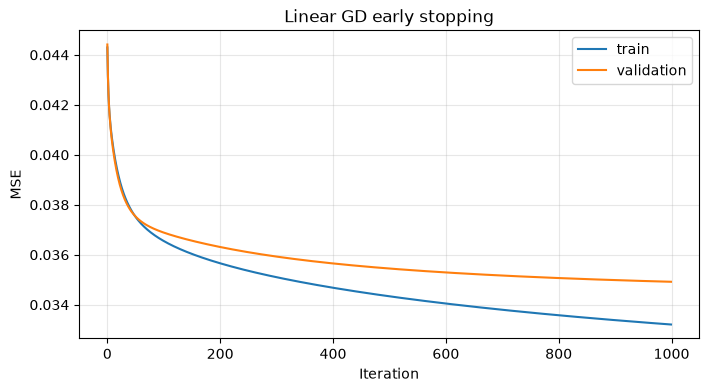

In [56]:
linear_gd_early_w, lingd_steps, linear_gd_best_val, linear_gd_train_loss, linear_gd_val_loss = fit_with_early_stopping(
    mse, grad_mse, X_fit, y_fit, X_tune, y_tune, step_size_gd, max_iters=max_iters_gd
)

plt.figure(figsize=(8, 4))
plt.plot(linear_gd_train_loss, label="train")
plt.plot(linear_gd_val_loss, label="validation")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Linear GD early stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# fit linear_gd with the early stopping weights
linear_gd_early = LinearRegressGD(max_iters=lingd_steps, gamma=step_size_gd, track_history=False)
linear_gd_early.w = linear_gd_early_w


Early stopping:   0%|          | 1547/5249000 [00:37<35:40:59, 40.85iter/s]


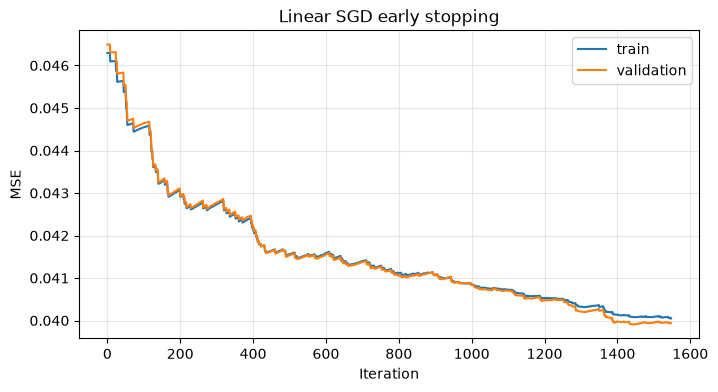

In [57]:
# Example use for the four gradient-based models.
def sgd_mse_grad(y, tx, w):
    n = np.random.randint(len(y))
    return grad_s_mse(y[n], tx[n], w)

linear_sgd_early_w, linsgd_steps, linear_sgd_best_val, linear_sgd_train_loss, linear_sgd_val_loss = fit_with_early_stopping(
    mse, sgd_mse_grad, X_fit, y_fit, X_tune, y_tune, step_size_sgd, max_iters=max_iters_sgd, patience=100
)

plt.figure(figsize=(8, 4))
plt.plot(linear_sgd_train_loss, label="train")
plt.plot(linear_sgd_val_loss, label="validation")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Linear SGD early stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

linear_sgd_early = LinearRegressSGD(max_iters=linsgd_steps, gamma=step_size_sgd, track_history=False)
linear_sgd_early.w = linear_sgd_early_w

Early stopping: 100%|██████████| 1000/1000 [01:01<00:00, 16.32iter/s]


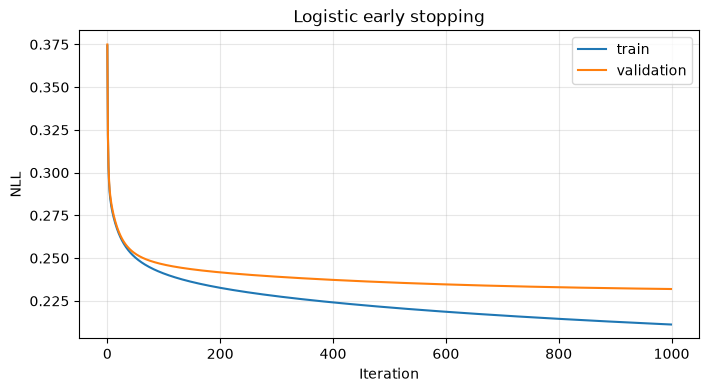

In [58]:
logistic_early_w, log_steps, logistic_best_val, logistic_train_loss, logistic_val_loss = fit_with_early_stopping(
    nll, grad_nll, X_fit, y_fit, X_tune, y_tune, step_size_logistic, max_iters=max_iters_logistic
)

plt.figure(figsize=(8, 4))
plt.plot(logistic_train_loss, label="train")
plt.plot(logistic_val_loss, label="validation")
plt.xlabel("Iteration")
plt.ylabel("NLL")
plt.title("Logistic early stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

logistic_early = LogisticRegress(max_iters=log_steps, gamma=step_size_logistic, track_history=False)
logistic_early.w = logistic_early_w

In [ ]:
from collections import defaultdict
from tqdm.auto import tqdm
from p1.modeling.train import mse, nll, grad_mse, grad_nll, grad_s_mse

def fit_with_early_stopping_with_lambda_search(

    loss_fn,
    grad_fn,
    x_train,
    y_train,
    x_valid,
    y_valid,
    gamma,
    max_iters=1000,
    patience=20,
    lambda_grid=np.logspace(-6, 2, 9)
):
    best_trial = None #defaultdict(lambda: None)

    for lambda_ in lambda_grid:
        w = np.zeros(x_train.shape[1])
        best_w = w.copy()
        best_val = np.inf
        steps_without_improvement = 0
        train_loss_history = []
        val_loss_history = []
        for step in tqdm(range(1, max_iters + 1), desc=f'Early stopping (lambda={lambda_:g})', unit='iter'):
            grad = grad_fn(y_train, x_train, w, lambda_)
            w = w - gamma * grad

            train_loss = float(loss_fn(y_train, x_train, w))
            val_loss = float(loss_fn(y_valid, x_valid, w))
            # train_loss_history.append(train_loss)
            # val_loss_history.append(val_loss)

            if val_loss < best_val:
                best_val = val_loss
                best_w = w.copy()
                steps_without_improvement = 0
            else:
                steps_without_improvement += 1
                if steps_without_improvement >= patience:
                    break

        # to get F1 we need to do a prediction
        reglin = LogisticRegress(max_iters=step, gamma=gamma, track_history=False)
        reglin.w = best_w
        f1_score = f1(y_valid, (reglin.predict(x_valid) >= 0.5).astype(float))
        trial = {
            'lambda_': lambda_,
            'weights': best_w,
            'f1': f1_score,
            # 'train_loss_history': train_loss_history,
            # 'val_loss_history': val_loss_history,
        }
        print(trial['lambda_'], trial['f1'])
        if best_trial is None or trial['f1'] >= best_trial['f1']:
            best_trial = trial
        
    return best_trial['lambda_'], best_trial['f1'], best_trial['weights']#, best_trial['train_loss_history'], best_trial['val_loss_history'], 



# reg_logistic_early_w, reg_logistic_best_f1, reg_logistic_train_loss, reg_logistic_val_loss, reg_logistic_early_lambda_ = fit_with_early_stopping_with_lambda_search(
reg_logistic_early_lambda_, reg_logistic_best_f1, reg_logistic_early_w = fit_with_early_stopping_with_lambda_search(
    nll,
    lambda y, x, w, lambda_: grad_nll(y, x, w) + 2 * lambda_ * w,
    X_fit,
    y_fit,
    X_tune,
    y_tune,
    step_size_logistic,
    max_iters=max_iters_logistic,
    # lambda_grid=lambda_grid,
)


Early stopping (lambda=1e-06): 100%|██████████| 1000/1000 [00:57<00:00, 17.36iter/s]


1e-06 0.31578947368421056


Early stopping (lambda=1e-05): 100%|██████████| 1000/1000 [01:00<00:00, 16.54iter/s]


1e-05 0.31578947368421056


Early stopping (lambda=0.0001): 100%|██████████| 1000/1000 [01:06<00:00, 14.93iter/s]


...

1.0 0.0


Early stopping (lambda=10):   2%|▏         | 22/1000 [00:01<01:19, 12.23iter/s]


10.0 0.0


Early stopping (lambda=100):   2%|▏         | 20/1000 [00:01<01:09, 14.19iter/s]

100.0 0.0


In [78]:
tmp = reg_logistic_early_lambda_.copy()
tmp2 = reg_logistic_early_w.copy()
reg_logistic_early_lambda_ = tmp2
reg_logistic_early_w = tmp

In [80]:

# plt.figure(figsize=(8, 4))
# plt.plot(reg_logistic_train_loss, label="train")
# plt.plot(reg_logistic_val_loss, label="validation")
# plt.xlabel("Iteration")
# plt.ylabel("NLL")
# plt.title("Regularized logistic early stopping")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.show()

reg_logistic_early = RegLogisticRegress(
    best_reg_logistic_lambda, max_iters=-1, gamma=step_size_logistic) # just need to wrap it

reg_logistic_early.w = reg_logistic_early_w


In [ ]:
# get metrics for the early stopping models on the test set
print('\nTest set evaluation (using best thresholds from validation split)')
print('Model                 Threshold  Accuracy  Precision  Recall    F1')

    

In [61]:
print(classification_metrics(linear_gd_early, y_valid, X_valid))

{'accuracy': np.float64(0.9071537290715372), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}


In [62]:
print(classification_metrics(linear_sgd_early, y_valid, X_valid))

{'accuracy': np.float64(0.9071537290715372), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}


In [63]:
print(classification_metrics(logistic_early, y_valid, X_valid))

{'accuracy': np.float64(0.9178082191780822), 'precision': np.float64(0.8888888888888888), 'recall': np.float64(0.13114754098360656), 'f1': np.float64(0.2285714285714286)}


In [81]:
print(classification_metrics(reg_logistic_early, y_valid, X_valid))

{'accuracy': np.float64(0.9178082191780822), 'precision': np.float64(0.8888888888888888), 'recall': np.float64(0.13114754098360656), 'f1': np.float64(0.2285714285714286)}


### Finally, combine
Early stopping and lambda search

Warning: there is no need to run the experiment. We can see that the same lambda - will do.



# Visualisations

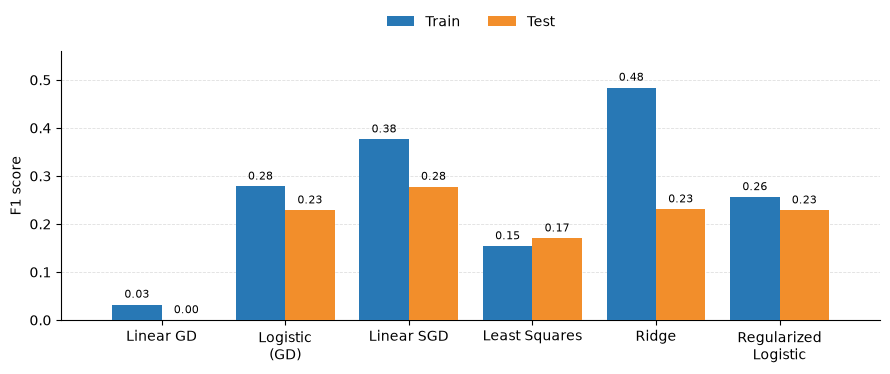

In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


models = [
    "Linear GD",
    "Logistic\n(GD)",
    "Linear SGD",
    "Least Squares",
    "Ridge",
    "Regularized\nLogistic",
]
train_f1 = [0.03225806451612903, 0.27823240589198034, 0.37639553429027117, 0.15399737876802094, 0.48411497730711045, 0.2562396006655574]
test_f1 = [0.0, 0.2285714285714286, 0.27777777777777773, 0.1702127659574468, 0.23076923076923075, 0.2285714285714286]

group_positions = np.arange(len(models)) * 0.8
bar_width = 0.32

fig, ax = plt.subplots(figsize=(9, 3.9))
train_bars = ax.bar(
    group_positions - bar_width / 2,
    train_f1,
    bar_width,
    label="Train",
    color="#2878B5",
    zorder=3,
)
test_bars = ax.bar(
    group_positions + bar_width / 2,
    test_f1,
    bar_width,
    label="Test",
    color="#F28E2B",
    zorder=3,
)

ax.bar_label(train_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(test_bars, fmt="%.2f", padding=3, fontsize=8)
ax.set_ylabel("F1 score")
ax.set_xticks(group_positions, models)
ax.set_ylim(0, 0.56)
ax.set_yticks(np.arange(0, 0.51, 0.1))
ax.set_xlim(group_positions[0] - 0.65, group_positions[-1] + 0.65)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.18))

fig.tight_layout()
# fig.savefig("Data/baseline_f1_comparison.pdf", bbox_inches="tight")


### baselines vs threshold tuned 

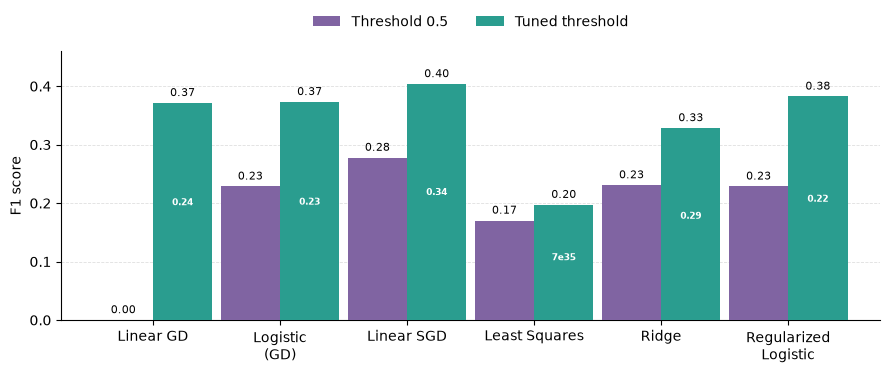

In [87]:
import matplotlib.pyplot as plt
import numpy as np


models = [
    "Linear GD",
    "Logistic\n(GD)",
    "Linear SGD",
    "Least Squares",
    "Ridge",
    "Regularized\nLogistic",
]
baseline_f1 = [0.0, 0.2285714285714286, 0.27777777777777773, 0.1702127659574468, 0.23076923076923075, 0.2285714285714286]
tuned_f1 = [0.3714, 0.3731, 0.4037, 0.1972, 0.3284, 0.3824]
threshold_labels = ["0.24", "0.23", "0.34", "7e35", "0.29", "0.22"]

group_positions = np.arange(len(models)) * 0.9
bar_width = 0.42
pair_offset = bar_width / 2

fig, ax = plt.subplots(figsize=(9, 3.9))
baseline_bars = ax.bar(
    group_positions - pair_offset,
    baseline_f1,
    bar_width,
    label="Threshold 0.5",
    color="#8064A2",
    zorder=3,
)
tuned_bars = ax.bar(
    group_positions + pair_offset,
    tuned_f1,
    bar_width,
    label="Tuned threshold",
    color="#2A9D8F",
    zorder=3,
)

ax.bar_label(baseline_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(tuned_bars, fmt="%.2f", padding=3, fontsize=8)
for position, score, threshold in zip(
    group_positions + pair_offset,
    tuned_f1,
    threshold_labels,
):
    ax.text(
        position,
        score * 0.54,
        threshold,
        ha="center",
        va="center",
        color="white",
        fontsize=6.5,
        fontweight="bold",
    )

ax.set_ylabel("F1 score")
ax.set_xticks(group_positions, models)
ax.set_ylim(0, 0.46)
ax.set_yticks(np.arange(0, 0.41, 0.1))
ax.set_xlim(group_positions[0] - 0.65, group_positions[-1] + 0.65)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.18))

fig.tight_layout()

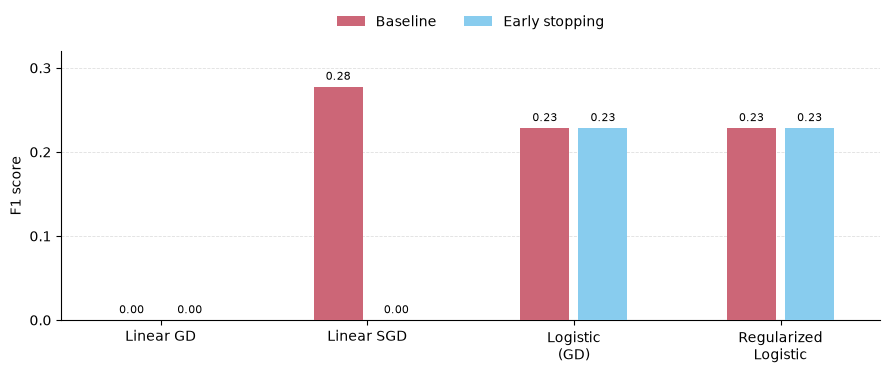

In [84]:
import matplotlib.pyplot as plt
import numpy as np


models = [
    "Linear GD",
    "Linear SGD",
    "Logistic\n(GD)",
    "Regularized\nLogistic",
]
baseline_f1 = [0.0, 0.27777777777777773, 0.2285714285714286, 0.2285714285714286]
early_stopping_f1 = [0.0, 0.0, 0.2285714285714286, 0.2285714285714286]

group_positions = np.arange(len(models)) * 1.35
bar_width = 0.32
pair_offset = bar_width / 2 + 0.03

fig, ax = plt.subplots(figsize=(9, 3.9))
baseline_bars = ax.bar(
    group_positions - pair_offset,
    baseline_f1,
    bar_width,
    label="Baseline",
    color="#CC6677",
    zorder=3,
)
early_stopping_bars = ax.bar(
    group_positions + pair_offset,
    early_stopping_f1,
    bar_width,
    label="Early stopping",
    color="#88CCEE",
    zorder=3,
)

ax.bar_label(baseline_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(early_stopping_bars, fmt="%.2f", padding=3, fontsize=8)
ax.set_ylabel("F1 score")
ax.set_xticks(group_positions, models)
ax.set_ylim(0, 0.32)
ax.set_yticks(np.arange(0, 0.31, 0.1))
ax.set_xlim(group_positions[0] - 0.65, group_positions[-1] + 0.65)
ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.18))

fig.tight_layout()
# fig.savefig("Data/early_stopping_f1_comparison.pdf", bbox_inches="tight")
# fig.savefig("Data/early_stopping_f1_comparison.png", dpi=300, bbox_inches="tight")

# 

#